# Notebook 01 — Pengambilan dataset dan pengelompokan kelas (Langkah 1)

Sumber: https://www.kaggle.com/datasets/cyanex1702/oceanic-life-dataset

Menyusun folder organisme laut seperti `flowers/daisy`, `flowers/rose`. Label asli folder/CSV/COCO diprioritaskan. Jika gambar belum berlabel, CLIP hanya membuat *usulan*; **wajib ditinjau dan disetujui** di `review_labels.csv` sebelum masuk data training.

Setelah selesai, lanjutkan `02_Praktikum_CNN_Langkah_1-8.ipynb`.

## 0. Install library dasar (jalankan satu kali)
Jika VS Code meminta restart kernel sesudah install, restart lalu mulai lagi dari sel berikutnya.

In [1]:
%pip install -q kagglehub Pillow pandas matplotlib tqdm

Note: you may need to restart the kernel to use updated packages.


## 1. Baca dataset Kaggle dan periksa struktur folder

Jika dataset sudah ada di Downloads, ubah `SOURCE_FOLDER` ke path yang tepat. Jika tidak, notebook mencoba mengunduh langsung dari Kaggle.

In [2]:
# Pengaturan proyek. Jika sudah ada folder Kaggle di Mac, isi SOURCE_FOLDER.
from pathlib import Path
import os, re, csv, json, shutil, hashlib, zipfile, warnings
from collections import Counter, defaultdict
from PIL import Image, UnidentifiedImageError
import pandas as pd

DATASET_SLUG = 'cyanex1702/oceanic-life-dataset'
PROJECT_DIR = Path.cwd().resolve()
# Contoh: SOURCE_FOLDER = Path('/Users/mochammadmarillivio/Downloads/Oceanic_Life-Dataset')
SOURCE_FOLDER = None   # Biarkan None agar dicari/diunduh otomatis
OUT_PARENT = PROJECT_DIR / 'hasil_pengelompokan'
FINAL_ROOT = OUT_PARENT / 'Oceanic_Life-Dataset'
PROPOSAL_ROOT = OUT_PARENT / 'Usulan_AI' / 'Oceanic_Life-Dataset'
UNLABELED_ROOT = OUT_PARENT / 'Belum_Berlabel'
REVIEW_CSV = OUT_PARENT / 'review_labels.csv'

CLASSES = ['Fish','Coral','Shark','Octopuses','Crustaceans','Seaweed','Sponges','Other marine organisms']
IMG_EXTS = {'.jpg','.jpeg','.png','.bmp','.webp','.tif','.tiff'}
GENERIC = {'dataset','oceanic life dataset','oceanic life','oceanic life dataset 1','images',
           'image','imgs','img','photos','pictures','all','raw','data','original',
           'train','training','valid','validation','val','test','testing','output',
           'archives','archive','samples','export','results','segmented','annotations',
           'labels','images train','images test'}
ALIAS = {
    'fish':'Fish', 'fishes':'Fish',
    'coral':'Coral','corals':'Coral','coral reef':'Coral',
    'shark':'Shark','sharks':'Shark',
    'octopus':'Octopuses','octopuses':'Octopuses','octopi':'Octopuses',
    'crustaceans':'Crustaceans','crustacean':'Crustaceans',
    'crab':'Crustaceans','crabs':'Crustaceans', 'lobster':'Crustaceans','lobsters':'Crustaceans',
    'shrimp':'Crustaceans','shrimps':'Crustaceans', 'prawn':'Crustaceans','prawns':'Crustaceans',
    'seaweed':'Seaweed','seaweeds':'Seaweed','kelp':'Seaweed','algae':'Seaweed',
    'sponge':'Sponges','sponges':'Sponges','sea sponge':'Sponges',
    'other marine organisms':'Other marine organisms',
    'other marine organism':'Other marine organisms','other marine objects':'Other marine organisms',
    'jellyfish':'Other marine organisms','starfish':'Other marine organisms',
    'sea turtle':'Other marine organisms','seahorse':'Other marine organisms',
    'sea anemone':'Other marine organisms'
}

def normalized(text):
    return ' '.join(re.findall(r'[a-z0-9]+', str(text).lower()))

def exact_category(text):
    return ALIAS.get(normalized(text))

def discover_images(root):
    root = Path(root)
    ignored = {'__macosx','.git','.ipynb_checkpoints','hasil_pengelompokan',
               'usulan_ai','belum_berlabel','output','.venv','venv'}
    result=[]
    for parent,dirs,files in os.walk(root):
        dirs[:] = [d for d in dirs if d.lower() not in ignored and not d.startswith('.')]
        for name in files:
            p=Path(parent)/name
            if p.suffix.lower() in IMG_EXTS and not name.startswith('.'):
                result.append(p)
    return sorted(result, key=lambda p:str(p).casefold())

def choose_source():
    if SOURCE_FOLDER is not None:
        p=Path(SOURCE_FOLDER).expanduser().resolve()
        if not p.is_dir(): raise FileNotFoundError(f'Folder tidak ditemukan: {p}')
        if not discover_images(p): raise FileNotFoundError(f'Folder belum berisi gambar: {p}')
        return p
    home=Path.home()
    candidates=[PROJECT_DIR/'Oceanic_Life-Dataset', PROJECT_DIR/'oceanic-life-dataset',
                PROJECT_DIR/'dataset', home/'Downloads'/'Oceanic_Life-Dataset',
                home/'Downloads'/'Oceanic_Life-Dataset'/'Oceanic_Life-Dataset',
                home/'Downloads'/'Praktikum_CNN_Oceanic_Life'/'dataset',
                home/'Downloads'/'Oceanic_Life_CNN'/'dataset']
    for p in candidates:
        if p.is_dir() and discover_images(p):
            print('Folder lokal ditemukan:',p)
            return p.resolve()
    print('Belum ada folder Oceanic Life lokal. Mengunduh dari Kaggle ...')
    import kagglehub
    p=Path(kagglehub.dataset_download(DATASET_SLUG)).resolve()
    if p.is_dir() and discover_images(p): return p
    zips=list(p.rglob('*.zip')) if p.is_dir() else ([p] if p.suffix.lower()=='.zip' else [])
    if zips:
        target=PROJECT_DIR/'dataset_ekstrak_oceanic'
        target.mkdir(exist_ok=True)
        for zpath in zips:
            with zipfile.ZipFile(zpath) as zf:
                for entry in zf.infolist():
                    dest=(target/entry.filename).resolve()
                    if not dest.is_relative_to(target.resolve()):
                        raise RuntimeError('Arsip ZIP mengandung path tidak aman.')
                zf.extractall(target)
        if discover_images(target): return target
    raise FileNotFoundError('Unduhan tidak berisi gambar yang terbaca. Periksa Kaggle atau SOURCE_FOLDER.')

DATA_DIR=choose_source()
PATHS=discover_images(DATA_DIR)
print('\nSUMBER DATASET:', DATA_DIR)
print('TOTAL GAMBAR TERDETEKSI:', len(PATHS))
print('12 CONTOH PATH:')
for p in PATHS[:12]: print(' •',p.relative_to(DATA_DIR))
print('FOLDER GAMBAR TERBANYAK:')
for dirname,n in Counter(str(p.parent.relative_to(DATA_DIR)) for p in PATHS).most_common(10):
    print(f' • {dirname}: {n}')
print('File CSV:',[str(p.relative_to(DATA_DIR)) for p in list(DATA_DIR.rglob('*.csv'))[:10]])

Belum ada folder Oceanic Life lokal. Mengunduh dari Kaggle ...

SUMBER DATASET: /Users/mochammadmarillivio/.cache/kagglehub/datasets/cyanex1702/oceanic-life-dataset/versions/1
TOTAL GAMBAR TERDETEKSI: 7960
12 CONTOH PATH:
 • OceanicLife Dataset/001v5h0d.jpg
 • OceanicLife Dataset/002ojjl6.jpg
 • OceanicLife Dataset/00dx9zud.JPG
 • OceanicLife Dataset/00gohyw5.jpg
 • OceanicLife Dataset/015e0ase.jpg
 • OceanicLife Dataset/015us06k.jpg
 • OceanicLife Dataset/017s6334.jpeg
 • OceanicLife Dataset/01cqbman.jpg
 • OceanicLife Dataset/01fifu6i.jpg
 • OceanicLife Dataset/01ji8io2.jpg
 • OceanicLife Dataset/01ly8g4q.jpg
 • OceanicLife Dataset/01n1y044.jpg
FOLDER GAMBAR TERBANYAK:
 • OceanicLife Dataset: 7960
File CSV: []


## 2. Deteksi label asli

Label yang benar dapat berasal dari folder kelas, CSV, atau anotasi COCO JSON. Nama kategori asal diubah menjadi kelas praktikum jika dapat dicocokkan secara eksplisit.

In [3]:
# Membaca label resmi dari folder kelas, metadata CSV, atau anotasi COCO JSON.
# TIDAK menganggap seluruh gambar dalam satu folder umum sebagai satu kelas.


def label_from_path(fp, root):
    # Label berdasarkan folder yang bernama organisme laut. Folder lebih dipercaya
    # dibanding nama berkas, dan kelas spesifik Shark diprioritaskan dibanding Fish.
    pieces=fp.relative_to(root).parts[:-1]
    found=[exact_category(s) for s in pieces]
    found=[x for x in found if x]
    if found:
        if len(set(found))==1: return found[-1], 'folder_kelas'
        return None, 'konflik_folder'
    # Hanya gunakan nama file kalau diawal ada token kategori utuh,
    # misalnya coral_001.jpg atau shark-001.png (bukan nomor acak).
    stem=normalized(fp.stem)
    matched=set()
    for raw,lab in ALIAS.items():
        if stem==raw or stem.startswith(raw+' '): matched.add(lab)
    if len(matched)==1: return matched.pop(), 'nama_file'
    return None,None


def unique_filename_index(paths, root):
    by_name=defaultdict(list); by_rel={}
    for fp in paths:
        by_name[fp.name.casefold()].append(fp)
        by_rel[str(fp.relative_to(root)).replace('\\','/').casefold()]=fp
    return by_name, by_rel


def match_file(value, by_name, by_rel):
    s=str(value).replace('\\','/').lstrip('./').strip().casefold()
    if s in by_rel: return by_rel[s]
    # Cukup cocokkan nama file ketika benar-benar unik.
    matches=by_name.get(Path(s).name,[])
    return matches[0] if len(matches)==1 else None


def csv_labels(root, paths):
    by_name,by_rel=unique_filename_index(paths,root)
    result={}; conflicts=set(); used=[]
    filecols={'filename','file name','file','image','image name','imagename',
              'image file','filepath','image path','path','img','image filename'}
    classcols={'label','labels','class','class name','classname','category',
               'category name','species','organism','type','target'}
    for csv_path in sorted(root.rglob('*.csv'))[:30]:
        try:
            if csv_path.stat().st_size>100_000_000: continue
            with open(csv_path,encoding='utf-8-sig',newline='') as fh:
                reader=csv.DictReader(fh)
                fieldnames=reader.fieldnames or []
                fcol=next((x for x in fieldnames if normalized(x) in filecols),None)
                ccol=next((x for x in fieldnames if normalized(x) in classcols),None)
                if not(fcol and ccol): continue
                count=0
                for rec in reader:
                    fp=match_file(rec.get(fcol,''),by_name,by_rel)
                    lab=exact_category(rec.get(ccol,''))
                    if fp is None or not lab: continue
                    if fp in result and result[fp]!=lab: conflicts.add(fp)
                    else: result[fp]=lab; count+=1
                if count: used.append((str(csv_path.relative_to(root)),count))
        except (OSError,UnicodeError,csv.Error) as exc: print('CSV dilewati:',csv_path.name,exc)
    for fp in conflicts: result.pop(fp,None)
    if used: print('Sumber CSV:', used[:5])
    return result


def coco_labels(root,paths):
    by_name,by_rel=unique_filename_index(paths,root)
    collected=defaultdict(set)
    for jf in sorted(root.rglob('*.json'))[:40]:
        try:
            if jf.stat().st_size>150_000_000: continue
            with open(jf,encoding='utf-8') as fh: obj=json.load(fh)
            if not isinstance(obj,dict) or not all(x in obj for x in ('images','annotations','categories')):
                continue
            catmap={d['id']: exact_category(d.get('name','')) for d in obj['categories']}
            impath={im['id']:match_file(im.get('file_name',''),by_name,by_rel) for im in obj['images']}
            for ann in obj['annotations']:
                fp=impath.get(ann.get('image_id'))
                lab=catmap.get(ann.get('category_id'))
                if fp and lab: collected[fp].add(lab)
        except (ValueError,KeyError,TypeError,OSError,UnicodeError): continue
    # Jika satu gambar memuat dua organisme berbeda, tidak dipaksakan menjadi satu label.
    return {fp:next(iter(v)) for fp,v in collected.items() if len(v)==1}

folder_labels={}
for fp in PATHS:
    label,method=label_from_path(fp,DATA_DIR)
    if label: folder_labels[fp]=(label,method)
labels_csv=csv_labels(DATA_DIR,PATHS)
labels_coco=coco_labels(DATA_DIR,PATHS)

# Perhatikan konflik label antar sumber.
labels={}; conflicts=[]
for fp in PATHS:
    proposed=[]
    if fp in folder_labels: proposed.append(folder_labels[fp][0])
    if fp in labels_csv: proposed.append(labels_csv[fp])
    if fp in labels_coco: proposed.append(labels_coco[fp])
    if len(set(proposed))>1:
        conflicts.append(fp)
        continue
    if proposed:
        method=folder_labels.get(fp,(None,'csv_json'))[1]
        labels[fp]=(proposed[0], method)

UNLABELED=[fp for fp in PATHS if fp not in labels]
print('\nLabel terverifikasi dari sumber:',len(labels))
print('Belum memiliki label/konflik:',len(UNLABELED))
print('Rincian label resmi:',dict(Counter(v[0] for v in labels.values())))
if conflicts:
    print('Gambar berlabel konflik:',len(conflicts),'(akan diperiksa, tidak dipaksakan)')


Label terverifikasi dari sumber: 0
Belum memiliki label/konflik: 7960
Rincian label resmi: {}


## 3. Usulan pengelompokan menggunakan CLIP (untuk gambar tanpa label)

**Prediksi otomatis bukan ground truth.** Gambar dipisahkan dalam folder `Usulan_AI` dan perlu pemeriksaan. Jika dataset sudah berlabel semua, CLIP tidak digunakan. Matikan lewat `JALANKAN_CLIP_JIKA_TANPA_LABEL=False` bila ingin memberi label secara manual.

In [4]:
# Tahap 3: Jika data asli TIDAK berlabel, CLIP memberi USULAN kategori dari isi gambar.
# Ini prediksi AI, BUKAN ground-truth. Simpan terpisah dan PERIKSA sebelum training.
# Kaggle dan bobot CLIP memerlukan internet saat pertama kali diakses.

JALANKAN_CLIP_JIKA_TANPA_LABEL = True
BATCH_CLIP = 16             # Kurangi menjadi 8 jika memori Mac terbatas
AI_PROPOSALS={}

if UNLABELED and JALANKAN_CLIP_JIKA_TANPA_LABEL:
    import importlib.util, subprocess, sys
    if importlib.util.find_spec('torch') is None or importlib.util.find_spec('transformers') is None:
        print('Memasang torch dan transformers untuk usulan pengelompokan ...')
        subprocess.check_call([sys.executable,'-m','pip','install','torch>=2.2,<3',
                               'transformers>=4.40,<5','tqdm>=4.60'])
    import torch
    from transformers import CLIPModel, CLIPProcessor
    from tqdm.auto import tqdm
    DEVICE=('mps' if hasattr(torch.backends,'mps') and torch.backends.mps.is_available()
            else 'cuda' if torch.cuda.is_available() else 'cpu')
    print('Memuat CLIP (unduhan bobot bisa cukup besar saat pertama kali) ... Device:',DEVICE)
    try:
        model=CLIPModel.from_pretrained('openai/clip-vit-base-patch32').to(DEVICE).eval()
        processor=CLIPProcessor.from_pretrained('openai/clip-vit-base-patch32')
        prompts=[
            'An underwater photograph of a fish with fins and scales.',
            'An underwater photograph of a coral colony or colorful coral reef.',
            'An underwater photograph of a shark.',
            'An underwater photograph of an octopus.',
            'An underwater photograph of a crab, lobster, shrimp or other crustacean.',
            'An underwater photograph of seaweed, ocean algae or kelp.',
            'An underwater photograph of a marine sea sponge.',
            'An underwater photograph of other marine organisms like jellyfish, starfish, anemones or sea turtles.'
        ]
        # Gunakan semua label sebagai kandidat; CLIP dapat salah sehingga jangan pakai
        # skor sebagai bukti benar. CSV akan berstatus HARUS_DICEK.
        for start in tqdm(range(0,len(UNLABELED),BATCH_CLIP),desc='Mengusulkan kelas AI'):
            group=UNLABELED[start:start+BATCH_CLIP]
            images=[]; valid_paths=[]
            for fp in group:
                try:
                    with Image.open(fp) as im:
                        im.load(); images.append(im.convert('RGB'))
                    valid_paths.append(fp)
                except (OSError,UnidentifiedImageError):
                    continue
            if not images: continue
            inputs=processor(text=prompts,images=images,return_tensors='pt',padding=True)
            inputs={k:v.to(DEVICE) for k,v in inputs.items()}
            with torch.no_grad():
                scores=model(**inputs).logits_per_image.float().softmax(dim=-1).cpu().numpy()
            for fp,probs in zip(valid_paths,scores):
                ix=int(probs.argmax())
                AI_PROPOSALS[fp]=(CLASSES[ix],round(float(probs[ix]),4))
        print('Jumlah usulan kelas dari AI:',len(AI_PROPOSALS))
    except Exception as exc:
        print('CLIP tidak bisa digunakan:',repr(exc))
        print('Gambar tetap dapat diekspor ke Belum_Berlabel untuk anotasi manual.')
else:
    print('CLIP tidak diperlukan/dinonaktifkan; menggunakan label asli jika tersedia.')

Memuat CLIP (unduhan bobot bisa cukup besar saat pertama kali) ... Device: mps


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


Mengusulkan kelas AI:   0%|          | 0/498 [00:00<?, ?it/s]

/opt/miniconda3/envs/ds/lib/python3.11/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Jumlah usulan kelas dari AI: 7952


## 4. Buat folder seperti `pengelompokan`

Folder setiap kelas dibuat otomatis, tanpa mengubah dataset asli. Gambar yang sudah punya label asli masuk `Oceanic_Life-Dataset`

In [5]:
# Tahap 4: Menyalin gambar menjadi folder PER KELAS.
# Sumber resmi otomatis masuk folder final; prediksi AI masuk folder Usulan_AI.
# Seluruh hasil disimpan pada folder hasil_pengelompokan (data sumber tidak diubah).

OUT_PARENT.mkdir(parents=True,exist_ok=True)
for root in (FINAL_ROOT,PROPOSAL_ROOT):
    for cls in CLASSES: (root/cls).mkdir(parents=True,exist_ok=True)
UNLABELED_ROOT.mkdir(parents=True,exist_ok=True)


def unique_dest(src,root,sub):
    stem=re.sub(r'[^A-Za-z0-9_.-]+','_',src.stem)[:55] or 'gambar'
    rel=str(src.relative_to(DATA_DIR))
    digest=hashlib.sha1(rel.encode('utf-8')).hexdigest()[:12]
    return root/sub/f'{stem}_{digest}{src.suffix.lower()}'

records=[]
for i,fp in enumerate(PATHS,1):
    if fp in labels:
        lab,method=labels[fp]
        status='DISETUJUI_DARI_LABEL_ASLI'
        dest=unique_dest(fp,FINAL_ROOT,lab)
        confidence=''
    elif fp in AI_PROPOSALS:
        lab,confidence=AI_PROPOSALS[fp]
        status='PERLU_REVIEW_AI'
        method='clip_zero_shot'
        dest=unique_dest(fp,PROPOSAL_ROOT,lab)
    else:
        lab=''; confidence=''; status='TANPA_LABEL'; method='tidak_tersedia'
        dest=unique_dest(fp,UNLABELED_ROOT,'')
    try:
        with Image.open(fp) as im: im.verify()
        dest.parent.mkdir(parents=True,exist_ok=True)
        if not dest.is_file() or dest.stat().st_size!=fp.stat().st_size:
            shutil.copy2(fp,dest)
        msg=''
    except (OSError,UnidentifiedImageError) as exc:
        status='GAMBAR_RUSAK'; msg=str(exc)[:150]; dest=''
    records.append({'path_sumber':str(fp.resolve()),'nama_file':fp.name,
                    'kelas_usulan':lab,'kelas_final':lab if status=='DISETUJUI_DARI_LABEL_ASLI' else '',
                    'status':status,'metode':method,'skor_ai':confidence,
                    'file_hasil':str(dest),'catatan':msg})
    if i%500==0: print(f'Disalinkan {i:,}/{len(PATHS):,} ...')

df_review=pd.DataFrame(records)
df_review.to_csv(REVIEW_CSV,index=False,encoding='utf-8-sig')
df_review['status'].value_counts().to_csv(OUT_PARENT/'ringkasan_status.csv',encoding='utf-8-sig')
print('\nLokasi folder klasifikasi final :',FINAL_ROOT)
print('Lokasi usulan AI (perlu review):',PROPOSAL_ROOT)
print('Gambar tanpa label           :',UNLABELED_ROOT)
print('CSV untuk pemeriksaan        :',REVIEW_CSV)
print('\nSTATUS:',df_review['status'].value_counts().to_dict())
print('\nJUMLAH LABEL ASLI PER KELAS:')
print(df_review[df_review.status=='DISETUJUI_DARI_LABEL_ASLI'].kelas_final.value_counts().to_string())
print('\nJUMLAH USULAN AI PER KELAS:')
print(df_review[df_review.status=='PERLU_REVIEW_AI'].kelas_usulan.value_counts().to_string())

Disalinkan 500/7,960 ...
Disalinkan 1,000/7,960 ...
Disalinkan 1,500/7,960 ...
Disalinkan 2,000/7,960 ...
Disalinkan 2,500/7,960 ...
Disalinkan 3,000/7,960 ...
Disalinkan 3,500/7,960 ...
Disalinkan 4,000/7,960 ...
Disalinkan 4,500/7,960 ...
Disalinkan 5,000/7,960 ...
Disalinkan 5,500/7,960 ...
Disalinkan 6,000/7,960 ...
Disalinkan 6,500/7,960 ...
Disalinkan 7,000/7,960 ...
Disalinkan 7,500/7,960 ...

Lokasi folder klasifikasi final : /Users/mochammadmarillivio/Downloads/Oceanic_Life_CNN_PERBAIKAN_FOLDER/hasil_pengelompokan/Oceanic_Life-Dataset
Lokasi usulan AI (perlu review): /Users/mochammadmarillivio/Downloads/Oceanic_Life_CNN_PERBAIKAN_FOLDER/hasil_pengelompokan/Usulan_AI/Oceanic_Life-Dataset
Gambar tanpa label           : /Users/mochammadmarillivio/Downloads/Oceanic_Life_CNN_PERBAIKAN_FOLDER/hasil_pengelompokan/Belum_Berlabel
CSV untuk pemeriksaan        : /Users/mochammadmarillivio/Downloads/Oceanic_Life_CNN_PERBAIKAN_FOLDER/hasil_pengelompokan/review_labels.csv

STATUS: {'PERLU_R

## 5. Setujui hasil yang telah ditinjau (opsional tapi diperlukan untuk data tanpa label)

Periksa gambar di `Usulan_AI`, edit `review_labels.csv` dengan `kelas_final` dan `status=DISETUJUI_MANUAL`, lalu jalankan ulang **hanya** sel di bawah ini. Jangan ulangi Tahap 4 setelah memperbaiki CSV.

In [6]:
# Tahap 5 (setelah memeriksa usulan AI): revisi review_labels.csv secara manual
# di Excel / VS Code. Atur 'kelas_final' dan 'status' = DISETUJUI_MANUAL.
# Lalu jalankan SEL INI SAJA untuk menghasilkan dataset kelas final.
# Jangan jalankan ulang sel ekspor sebelumnya sesudah mengedit CSV karena itu
# akan menulis ulang review_labels.csv.

def ekspor_label_yang_disetujui():
    d=pd.read_csv(REVIEW_CSV,dtype=str,keep_default_na=False)
    approved=d[d.status.isin({'DISETUJUI_MANUAL','DISETUJUI_DARI_LABEL_ASLI'})]
    approved=approved[approved.kelas_final.isin(CLASSES)]
    counts=Counter(); skipped=[]
    for _,r in approved.iterrows():
        src=Path(r['path_sumber']); cat=r['kelas_final']
        if not src.is_file(): skipped.append(str(src)); continue
        dest=unique_dest(src,FINAL_ROOT,cat)
        dest.parent.mkdir(exist_ok=True,parents=True)
        if not dest.is_file() or dest.stat().st_size!=src.stat().st_size:
            shutil.copy2(src,dest)
        counts[cat]+=1
    print('File berlabel disetujui (termasuk label asli):',sum(counts.values()))
    print('Distribusi:',dict(counts))
    if skipped: print('File yang sudah tidak ada:',len(skipped))
    if len([n for n in counts.values() if n])<2:
        print('PERHATIAN: Untuk training CNN diperlukan minimal 2 kelas berisi gambar yang disetujui.')
    else:
        print('Folder siap dibaca Keras image_dataset_from_directory:',FINAL_ROOT)
    return counts

hasil_pemeriksaan=ekspor_label_yang_disetujui()

File berlabel disetujui (termasuk label asli): 0
Distribusi: {}
PERHATIAN: Untuk training CNN diperlukan minimal 2 kelas berisi gambar yang disetujui.


## 6. Periksa folder FINAL sebelum membuka Notebook 02

Folder `Oceanic_Life-Dataset` baru siap digunakan apabila **minimal dua kelas berisi gambar**. Jika hanya `Usulan_AI` yang terisi, itu adalah **prediksi yang belum diverifikasi**, bukan ground truth. Tinjau `hasil_pengelompokan/review_labels.csv`, isi `kelas_final`, ubah `status` menjadi `DISETUJUI_MANUAL` untuk setiap gambar yang benar-benar sudah ditinjau, simpan file CSV, lalu jalankan sel persetujuan. Notebook 02 yang baru dapat menyalin baris yang sudah disetujui secara otomatis.

Alternatif yang lebih nyaman: jalankan `python -m streamlit run 03_Tinjau_Label.py` di terminal untuk meninjau gambar satu per satu melalui halaman web.


Contoh struktur output:
hasil_pengelompokan/
├── Oceanic_Life-Dataset/   ← gambar dengan label asli/disetujui
│   ├── Fish : 0 gambar
│   ├── Coral : 0 gambar
│   ├── Shark : 0 gambar
│   ├── Octopuses : 0 gambar
│   ├── Crustaceans : 0 gambar
│   ├── Seaweed : 0 gambar
│   ├── Sponges : 0 gambar
│   ├── Other marine organisms : 0 gambar
├── Usulan_AI/Oceanic_Life-Dataset/   ← prediksi AI (PERLU DICEK)
│   ├── Fish : 2596 gambar
│   ├── Coral : 759 gambar
│   ├── Shark : 1013 gambar
│   ├── Octopuses : 377 gambar
│   ├── Crustaceans : 760 gambar
│   ├── Seaweed : 882 gambar
│   ├── Sponges : 455 gambar
│   ├── Other marine organisms : 1110 gambar
├── Belum_Berlabel/
└── review_labels.csv


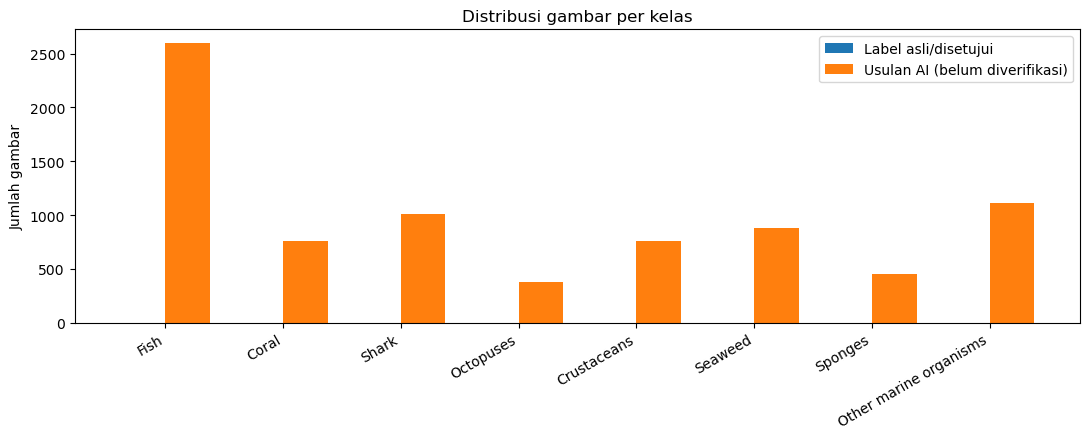

In [7]:
# Pemeriksaan folder akhir dan visualisasi distribusi gambar.
import matplotlib.pyplot as plt
from IPython.display import display

print('Contoh struktur output:')
print('hasil_pengelompokan/')
print('├── Oceanic_Life-Dataset/   ← gambar dengan label asli/disetujui')
for name in CLASSES: print('│   ├──',name,':',len(discover_images(FINAL_ROOT/name)),'gambar')
print('├── Usulan_AI/Oceanic_Life-Dataset/   ← prediksi AI (PERLU DICEK)')
for name in CLASSES: print('│   ├──',name,':',len(discover_images(PROPOSAL_ROOT/name)),'gambar')
print('├── Belum_Berlabel/')
print('└── review_labels.csv')

approved_counts=[len(discover_images(FINAL_ROOT/c)) for c in CLASSES]
proposal_counts=[len(discover_images(PROPOSAL_ROOT/c)) for c in CLASSES]
fig, ax=plt.subplots(figsize=(11,4.5))
x=list(range(len(CLASSES)))
ax.bar([i-.19 for i in x],approved_counts,width=.38,label='Label asli/disetujui')
ax.bar([i+.19 for i in x],proposal_counts,width=.38,label='Usulan AI (belum diverifikasi)')
ax.set_xticks(x,CLASSES,rotation=30,ha='right')
ax.set_ylabel('Jumlah gambar');ax.set_title('Distribusi gambar per kelas')
ax.legend();fig.tight_layout()
fig.savefig(OUT_PARENT/'grafik_distribusi_pengelompokan.png',dpi=130)
plt.show()

## 7. Pemakaian untuk CNN

Gunakan folder **`hasil_pengelompokan/Oceanic_Life-Dataset`** sebagai dataset CNN **hanya setelah minimal dua kelas sudah berisi gambar berlabel resmi/disetujui**.

Contoh pembacaan di Keras:

```python
import tensorflow as tf
train_ds = tf.keras.utils.image_dataset_from_directory(
    'hasil_pengelompokan/Oceanic_Life-Dataset',
    validation_split=0.2, subset='training', seed=42,
    image_size=(128, 128), batch_size=32
)
```

Pembagian train/validation/test yang lebih teliti dan stratified dibuat saat praktikum training; kode di atas hanya contoh pengecekan pembacaan kelas.